In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")

# Convertir las columnas de fechas de orders

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 1 Línea: pedidos por mes plt.plot
Cargar orders y convertir order_purchase_timestamp a datetime.

Filtrar order_status == 'delivered' (opcional).

Crear columna de mes con .dt.to_period('M').

groupby por mes y contar order_id con nunique.

Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena lección de "mira tus datos antes de graficar".

Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.


,order_purchase_timestamp,order_id,month
81171,2017-12-09 17:14:00,a16fc9188775803f3b6fcaf961d974c0,2017-12
44573,2018-07-03 22:13:48,ae213a9f84c777fb7a31e8c0f09fd30c,2018-07
32834,2017-08-11 11:58:43,0d5f49b8f9f7176361444dcc91621776,2017-08
57262,2018-06-07 11:12:43,9a613bed98997c9e9969a5b93500f491,2018-06
11241,2018-02-22 16:06:29,c801ee070159af89f5ce2b8c03e9e032,2018-02


<Axes: title={'center': 'Numero de ventas por mes'}, xlabel='mes', ylabel='Cantidad de ventas'>

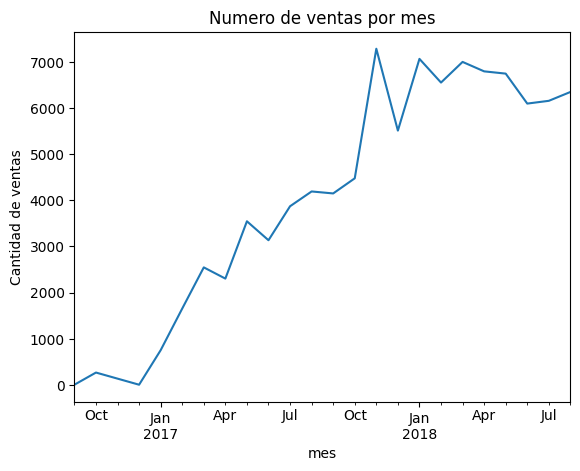

In [21]:
# sólo ventas entregadas
df1 = orders[orders["order_status"] == "delivered"]

# para evitar saturar la emoria de sólo las columnas que necesito
df1 = df1[["order_purchase_timestamp","order_id"]]

# Crear una columna mes a partirde "order_purcharse_timestamp" 
df1["month"] = df1["order_purchase_timestamp"].dt.to_period('M')

# utilizo sample(5) para mostrar 5 elementos aleatorios del dataframe
display(df1.sample(5))

# agrupar por mes y contar order_id
resultado = df1.groupby("month")["order_id"].nunique()

# ahora va el plot, fecha vs valor numérico equivale a un line plot
resultado.plot(
    kind = "line",
    xlabel = "mes",
    ylabel = "Cantidad de ventas",
    title = "Numero de ventas por mes"
)

# 2 Barras horizontales: top 10 categorías por ingreso plt.barh
Merge order_items + products por product_id.

Merge con product_category_name_translation por product_category_name (nombres en inglés).

groupby categoría → suma de price.

Tomar las 10 mayores con .nlargest(10).

Invertir el orden para que la mayor quede arriba y graficar con barh.


<Axes: ylabel='product_category_name'>

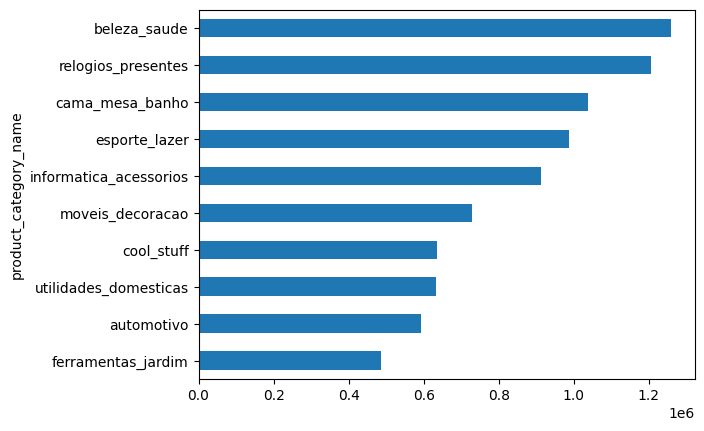

In [22]:
df1 = order_items[["product_id","price"]]
df2 = products[["product_id","product_category_name"]]
df3 = df2.merge(df1, on = "product_id", how = "left")
resultado2 = df3.groupby("product_category_name")["price"].sum().nlargest(10).sort_values(ascending = True)
resultado2.plot(
    kind = "barh"
)

# 3 Histograma: distribución del precio plt.hist
Usar order_items['price'].

Primer histograma directo: se verá muy sesgado.

Repetir con bins en escala log o con np.log10(price).

Discusión: por qué la media engaña. Marcar media y mediana con axvline.


<Axes: ylabel='Frequency'>

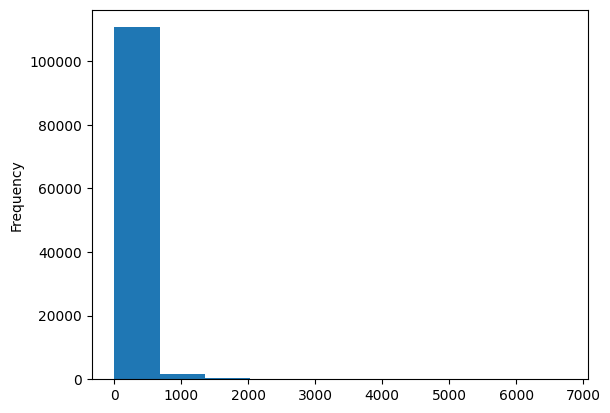

In [23]:
df1 = order_items["price"]
df1.plot(
    kind = "hist"
)

In [24]:
import numpy as np
df5 = order_items
df5["log"] = df5["price"].apply(np.log10)

<Axes: >

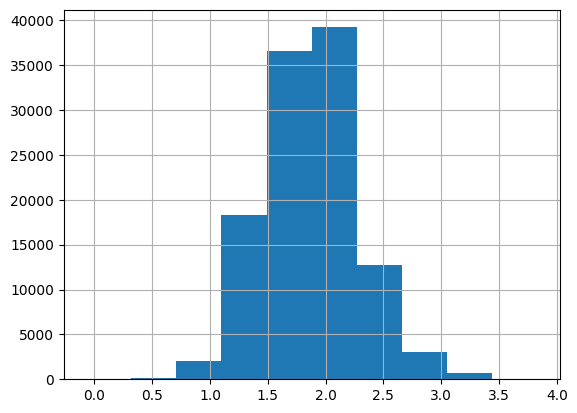

In [25]:
df5["log"].hist()

# 4 Histograma comparativo: días de entrega reales vs. estimado hist + alpha
En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.

Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).

Eliminar NaN (pedidos no entregados).

Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

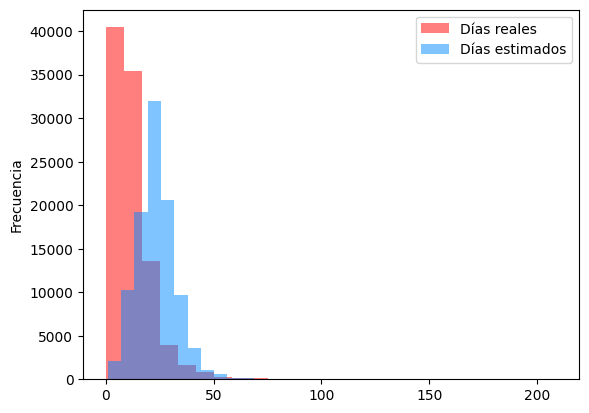

In [26]:
dias_reales = (orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]).dt.days
dias_estimados = (orders["order_estimated_delivery_date"] - orders["order_purchase_timestamp"]).dt.days
dias_reales = dias_reales.dropna()
dias_estimados = dias_estimados.dropna()
ax1 = dias_reales.plot(
    kind = "hist",
    color ="#ff0000",
    alpha = 0.5,
    bins = 25,
    label = "Días reales",
    ylabel = "Frecuencia"
)
ax2 = dias_estimados.plot(
    kind= "hist",
    color ="#0088ff",
    alpha = 0.5,
    bins = 25,
    label = "Días estimados",
    ylabel = "Frecuencia"
)
ax1.legend()
plt.show()

# 5 Boxplot: calificación vs. días de retraso plt.boxplot
En orders, calcular retraso = entregado − estimado en días.

Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).

Agrupar el retraso por review_score (1–5) → lista de 5 arrays.

Pasar la lista a boxplot con etiquetas 1–5.

Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.


C:\Users\scril\AppData\Local\Temp\ipykernel_35812\1275381317.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(lista,labels=[1,2,3,4,5])


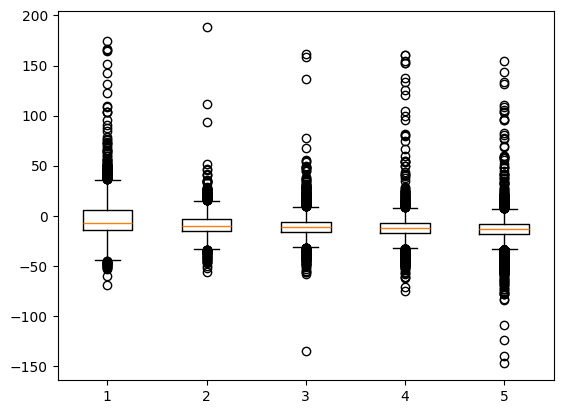

In [27]:
orders["retraso"] = (orders["order_delivered_customer_date"]-orders["order_estimated_delivery_date"]).dt.days
merge = orders.merge(order_reviews, on = "order_id", how = "left").drop_duplicates(subset="order_id")
merge = merge.dropna(subset="retraso")
lista = [merge[merge["review_score"] == calif]["retraso"] for calif in range(1, 6)]
fig, ax = plt.subplots()
ax.boxplot(lista,labels=[1,2,3,4,5])
plt.show()

# 6 Barras con error: calificación promedio a tiempo vs. tarde plt.bar(yerr=)
Usar el mismo merge de la gráfica 5.

Crear columna booleana tarde = retraso > 0.

groupby('tarde') → mean y std de review_score.

Graficar barras con yerr=std.


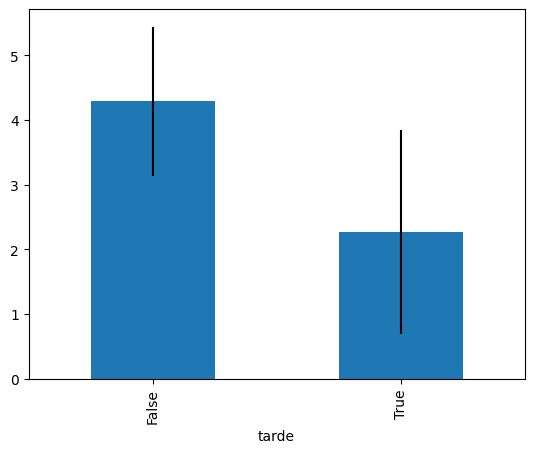

In [28]:
merge["tarde"] = (merge["retraso"]>0)
merge = merge.dropna(subset="retraso")
tarde_con_review = merge.groupby("tarde")["review_score"].agg(["mean","std"])
ax3 = tarde_con_review["mean"].plot(kind="bar",
                            yerr = tarde_con_review["std"])

# 7 Pastel / dona: métodos de pago plt.pie
order_payments → value_counts() de payment_type.

Agrupar not_defined y categorías pequeñas en "otros".

Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.

Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.


<Axes: ylabel='count'>

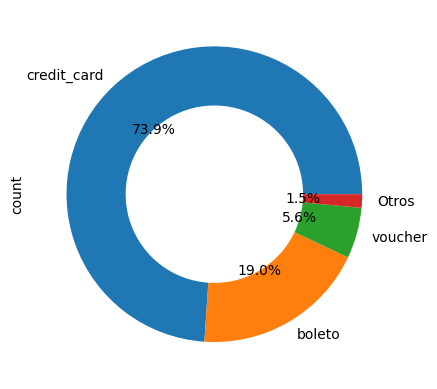

In [29]:
df8 = payments["payment_type"].value_counts().head(3)
df8["Otros"] = payments["payment_type"].value_counts().iloc[3:].sum()
df8.plot(kind = "pie",
         autopct="%1.1f%%",
         wedgeprops={"width":0.4})

# 8 Barras agrupadas: monto promedio por mensualidades y método de pago pivot + bar
Tomar order_payments.

Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.

pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.

Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).


C:\Users\scril\AppData\Local\Temp\ipykernel_35812\1136028309.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pibble = payments.pivot_table(index="rangos",columns="payment_type",values="payment_value",aggfunc="mean")


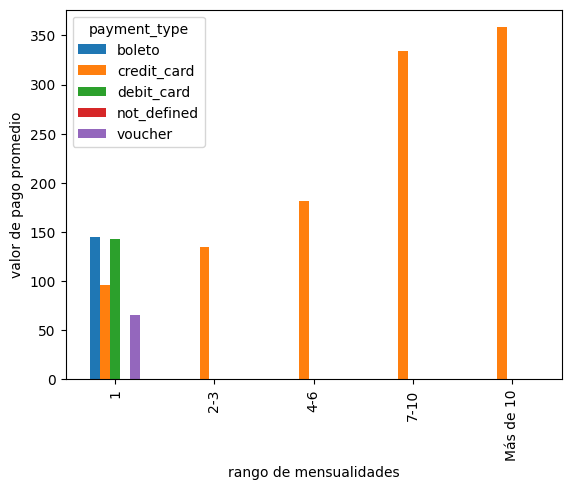

In [30]:
payments["rangos"] = pd.cut(payments["payment_installments"],
                            bins=[0,1,3,6,10,np.inf],
                            labels = ["1","2-3","4-6","7-10","Más de 10"])
pibble = payments.pivot_table(index="rangos",columns="payment_type",values="payment_value",aggfunc="mean")
pibble.plot(kind="bar", 
            ylabel = "valor de pago promedio",
            xlabel = "rango de mensualidades")
plt.show()


# 9 Barras apiladas: estado del pedido por estado de la república pivot + bottom=
Merge orders + customers por customer_id.

pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.

Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.

Quedarse con los 10 estados con más pedidos.

Apilar barras con un loop acumulando bottom.

<Axes: xlabel='Estado de orden', ylabel='Proporcion de pedidos'>

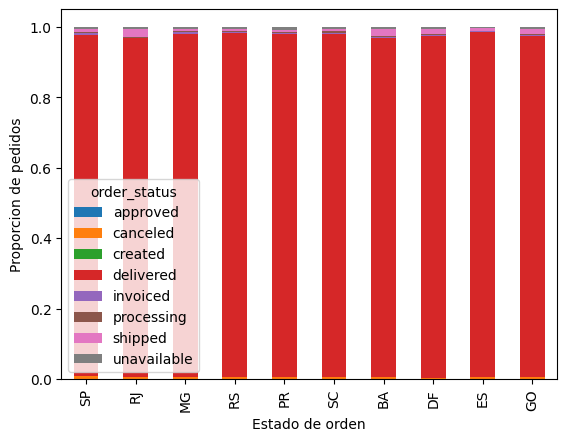

In [31]:
merge1 = orders.merge(customers, on="customer_id", how = "left")
pibble_2 = merge1.pivot_table(index = "customer_state",columns = "order_status",values= "order_id",aggfunc="count",fill_value=0)
pibble2_suma = pibble_2.sum(axis=1)
pibble2_division = pibble_2.div(pibble2_suma,axis=0)
pibble2_division_10 = pibble2_division.loc[pibble2_suma.nlargest(10).index]
pibble2_division_10.plot(kind="bar",
                         stacked="True",
                         xlabel="Estado de orden",
                         ylabel = "Proporcion de pedidos")

# 10 Dispersión: peso del producto vs. costo de envío plt.scatter
Merge order_items + products por product_id.

Tomar product_weight_g y freight_value; quitar NaN.

Muestrear con .sample(3000) (110k puntos saturan la gráfica).

Graficar con alpha bajo; opcionalmente ejes en escala log.

Extra: colorear por price con c= y agregar plt.colorbar().

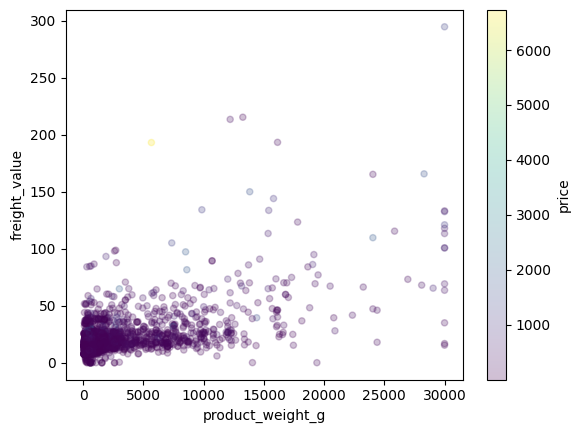

In [32]:
merge2 = order_items.merge(products,on="product_id",how="left")
merge2_sinNANS = merge2[["product_weight_g","freight_value","price"]].dropna()
merge2_sample = merge2_sinNANS.sample(3000)
merge2_sample.plot(kind="scatter",
                   x="product_weight_g",
                   y="freight_value",
                   c="price",
                   alpha = 0.25)
plt.show()

# 11 Mapa de calor: pedidos por día de la semana × hora pivot + imshow
1. De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.

2. pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.

3. plt.imshow(pivot, aspect='auto', cmap='YlOrRd') .

4. Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.

5. Extra: escribir valores en las celdas con doble loop de ax.text

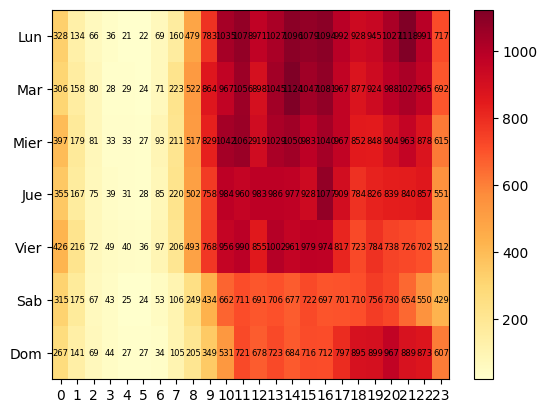

In [33]:
orders["dias_semana"] = orders["order_purchase_timestamp"].dt.dayofweek
orders["horas"] = orders["order_purchase_timestamp"].dt.hour
pibble3 =  orders.pivot_table(index ="dias_semana", columns = "horas", values= "order_id",aggfunc="count")
mapa = plt.imshow(pibble3,aspect="auto",cmap ="YlOrRd" )
plt.yticks(range(7),["Lun","Mar","Mier","Jue","Vier","Sab","Dom"])
plt.xticks(range(24))
plt.colorbar(mapa)
for i in range(7):
    for j in range(24):
        plt.text(j, i, pibble3.iloc[i, j],  ha="center", va="center",fontsize=6)

# 12 Dashboard final: subplots + doble eje plt.subplots + twinx
Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.

fig, axes = plt.subplots(2, 2, figsize=(14,10)).

Panel 1: pedidos por mes y, con twinx(), ingreso mensual en el segundo eje (merge orders + order_items, groupby mes, suma de price).

Demás paneles: top categorías, boxplot de reseñas y heatmap.

fig.suptitle, plt.tight_layout() y savefig('dashboard.png', dpi=150).

C:\Users\scril\AppData\Local\Temp\ipykernel_35812\3788551778.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1,0].boxplot(cinco,labels=[1,2,3,4,5])


(Text(0.5, 0.98, 'ejercicio 12'), None, None)

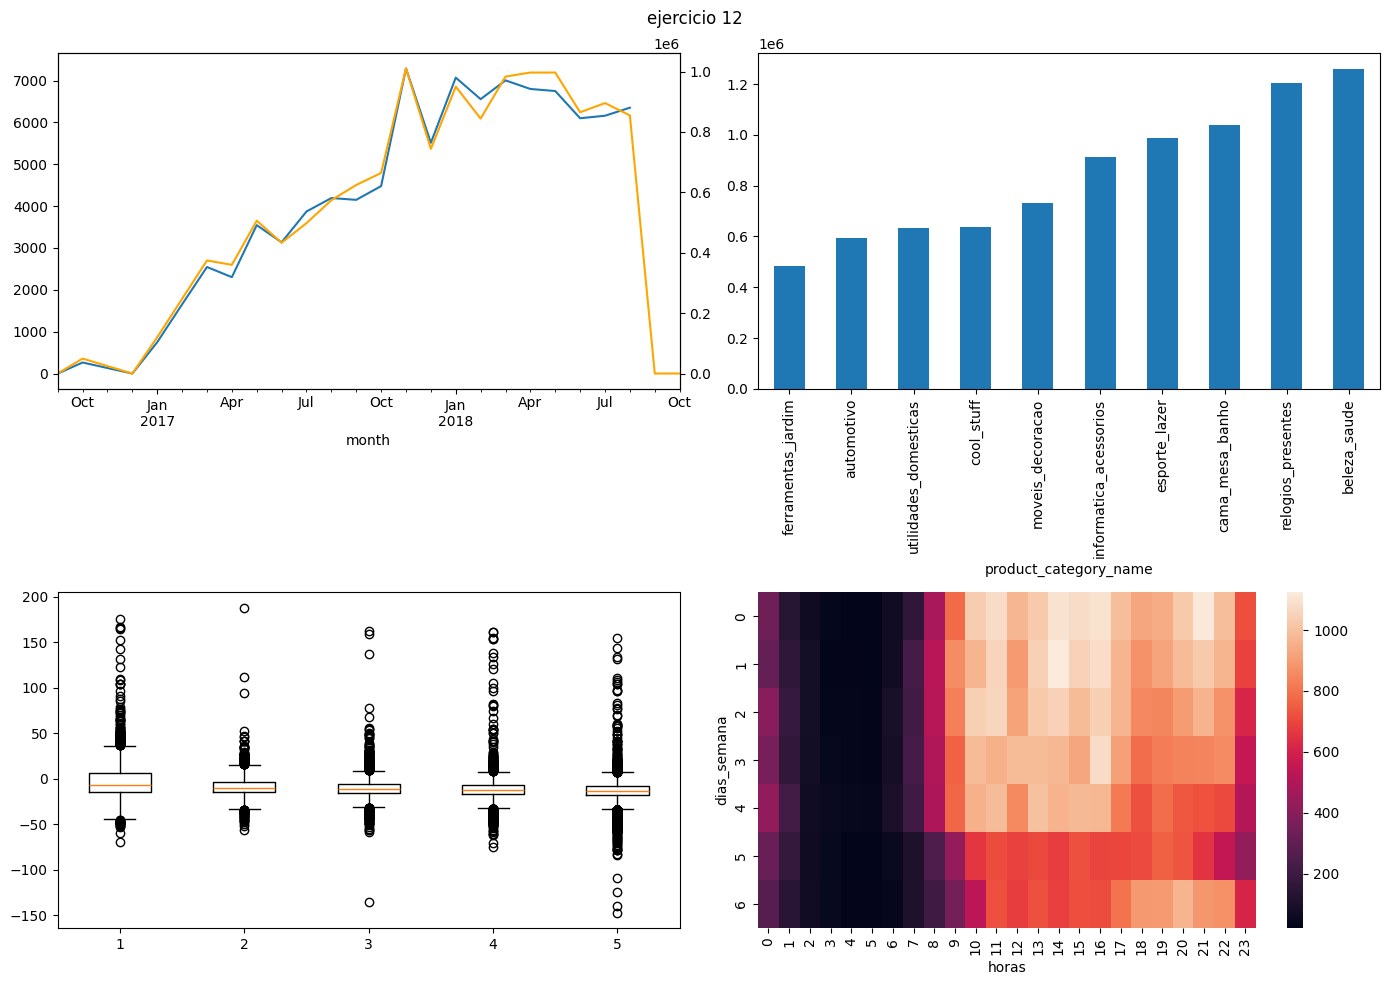

In [35]:
uno = resultado
dos = resultado2
cinco = lista
once = pibble3
fig, axes = plt.subplots(2,2,figsize=(14,10))
uno.plot(ax=axes[0,0])
ingreso_mensual = orders.merge(order_items, on = "order_id", how = "left")
ingreso_mensual["month"] = ingreso_mensual["order_purchase_timestamp"].dt.to_period('M')
ingreso = ingreso_mensual.groupby("month")["price"].sum()
ax2 = axes[0,0].twinx()
ingreso.plot(ax=ax2, color="orange")
dos.plot(kind = "bar",
         ax=axes[0,1])
axes[1,0].boxplot(cinco,labels=[1,2,3,4,5])
sns.heatmap(once,ax=axes[1,1])
fig.suptitle("ejercicio 12"), plt.tight_layout(), plt.savefig('dashboard.png', dpi=150)